# Train Wagons Planning — Benchmark, Checks and Plans

*© 2026 Taras Bulubas — all rights reserved. You may open, run and modify this
notebook in Google Colab for personal, non-commercial exploration; any other
use requires prior written permission. See `LICENSE`.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tbulubas/train-wagons-planning/blob/main/notebooks/benchmark.ipynb)

How far does a **single pure MILP** go for this loading problem, and how do we
know its plans are right? This notebook

1. reads the benchmark results in `docs/benchmark/` and shows where the
   solvers prove optimality, how large the gaps are, and why;
2. repeats the most important check of the tests live — the MILP against an
   exhaustive search on tiny instances;
3. draws and replays optimal plans: the port, the FIFO lanes of the buffer and
   the departure track.

The problem is described in [`docs/problem-statement.md`](../docs/problem-statement.md),
the model in [`docs/mip-model.md`](../docs/mip-model.md).

**Where it runs**

- **Google Colab** — open it with the badge above and choose *Runtime → Run all*.
  The first code cell fetches the repository from GitHub (the benchmark results
  and the tests) and installs the `train_wagons` package, which takes about a
  minute. Your changes stay in your own copy; save it with *File → Save a copy
  in Drive* to keep them.
- **Locally** — `make notebook` opens it in JupyterLab in the project's `.venv`,
  which already has everything; the first cell then does nothing.
  `make notebook-check` runs all cells headless.

In [1]:
import importlib
import importlib.util
import subprocess
import sys
from pathlib import Path

REPOSITORY = "https://github.com/tbulubas/train-wagons-planning.git"

here = Path.cwd()
ROOT = here.parent if here.name == "notebooks" else here
if not (ROOT / "docs" / "benchmark").is_dir():  # e.g. Google Colab: fetch the repository once
    ROOT = here / "train-wagons-planning"
    if not ROOT.is_dir():
        print("Cloning the repository from GitHub …")
        subprocess.check_call(["git", "clone", "--quiet", "--depth", "1", REPOSITORY, str(ROOT)])
if importlib.util.find_spec("train_wagons") is None:
    print("Installing the train_wagons package …")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", f"{ROOT}[dev,plot]"])  # dev: pytest for the checks
    importlib.invalidate_caches()
print("ready: repository", ROOT.name)

ready: repository PlanningTrainWagons


In [2]:
import sys
import warnings
from glob import glob
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
import pandas as pd
from IPython.display import HTML, display

sys.path.insert(0, str(ROOT / "tests"))  # the exhaustive search lives with the tests

from train_wagons import YardInstance, random_instance, simulate
from train_wagons.draw import draw_yard, yard_states
from train_wagons.model import ModelOptions, solve
from train_wagons.viewer import viewer_html

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
CONFIGS = ["cp-sat", "scip", "cp-sat+start", "scip+start"]

## 1 · The benchmark

Every row is one random instance solved in one configuration, for the first
criterion only — the **number of changes of goods** — with a time limit of
60 s.

| column | meaning |
|---|---|
| `series` | `grid`: the number of lanes N is chosen for a target load factor λ; `N=26`: the reference buffer of 26 lanes |
| `K`, `W`, `N` | trains, wagons, lanes |
| `load_factor` | λ = total load weight / (N · 30 t); above 1 not all wagons fit at once |
| `heuristic` | changes of the best heuristic plan, an upper bound |
| `R`, `variables` | run slots and size of the model |
| `solver` | `cp-sat`, `scip` — the pure model; `+start` — started from the heuristic plan |
| `status`, `value`, `bound` | solver status, best plan, best lower bound |

In [3]:
frames = [pd.read_csv(path) for path in sorted(glob(str(ROOT / "docs" / "benchmark" / "*.csv")))]
df = pd.concat(frames, ignore_index=True)
df["label"] = np.where(df.series == "N=26", "N = 26", "λ ≈ " + df.target.astype(str))
df["proved"] = df.status == "optimal"
df["found"] = df.value.notna()
df["gap"] = df.value - df.bound
print(f"{len(df)} runs: {df.groupby(['series', 'K', 'target', 'seed']).ngroups} instances × {df.solver.nunique()} configurations")
assert df.valid.dropna().astype(bool).all(), "a plan failed the check with simulate"
df.head()

280 runs: 70 instances × 4 configurations


,series,K,target,seed,W,N,load_factor,goods,heuristic,R,...,solver,status,value,bound,seconds,valid,label,proved,found,gap
0,grid,4,1,1,30,4,1.00,4,3,4,...,cp-sat+start,optimal,3.0,3.0,0.1,True,λ ≈ 1,True,True,0.0
1,grid,4,1,2,36,7,0.95,4,3,4,...,cp-sat+start,optimal,3.0,3.0,0.1,True,λ ≈ 1,True,True,0.0
2,grid,6,1,1,51,9,0.95,4,3,4,...,cp-sat+start,optimal,3.0,3.0,0.3,True,λ ≈ 1,True,True,0.0
3,grid,6,1,2,58,10,0.99,4,3,4,...,cp-sat+start,optimal,3.0,3.0,0.4,True,λ ≈ 1,True,True,0.0
4,grid,8,1,1,76,12,1.00,4,3,4,...,cp-sat+start,optimal,3.0,3.0,0.9,True,λ ≈ 1,True,True,0.0


In [4]:
summary = df.groupby("solver").agg(
    runs=("proved", "size"), optimal=("proved", "sum"), plan_found=("found", "sum"),
    median_seconds_to_optimum=("seconds", lambda s: s[df.loc[s.index, "proved"]].median()),
).reindex(CONFIGS)
summary

,runs,optimal,plan_found,median_seconds_to_optimum
solver,,,,
cp-sat,70,39,46,3.1
scip,70,11,13,17.3
cp-sat+start,70,44,68,2.4
scip+start,70,15,40,0.4


**Reading.** CP-SAT proves the optimum on roughly every second instance and,
with a start, finds a plan for almost all of them. SCIP proves only a small
fraction; without a start it often does not even find a first plan within
the minute. Every plan that was found passed the independent check with
`simulate` (the `assert` above).

### Where is optimality proved?

One map per configuration: columns are the number of trains, rows the load
factor. Green — both instances of the cell proved optimal; yellow — plans,
but no proof; grey — no plan. The text shows the best plan of each instance
and, in brackets, the lower bound when the gap is open.

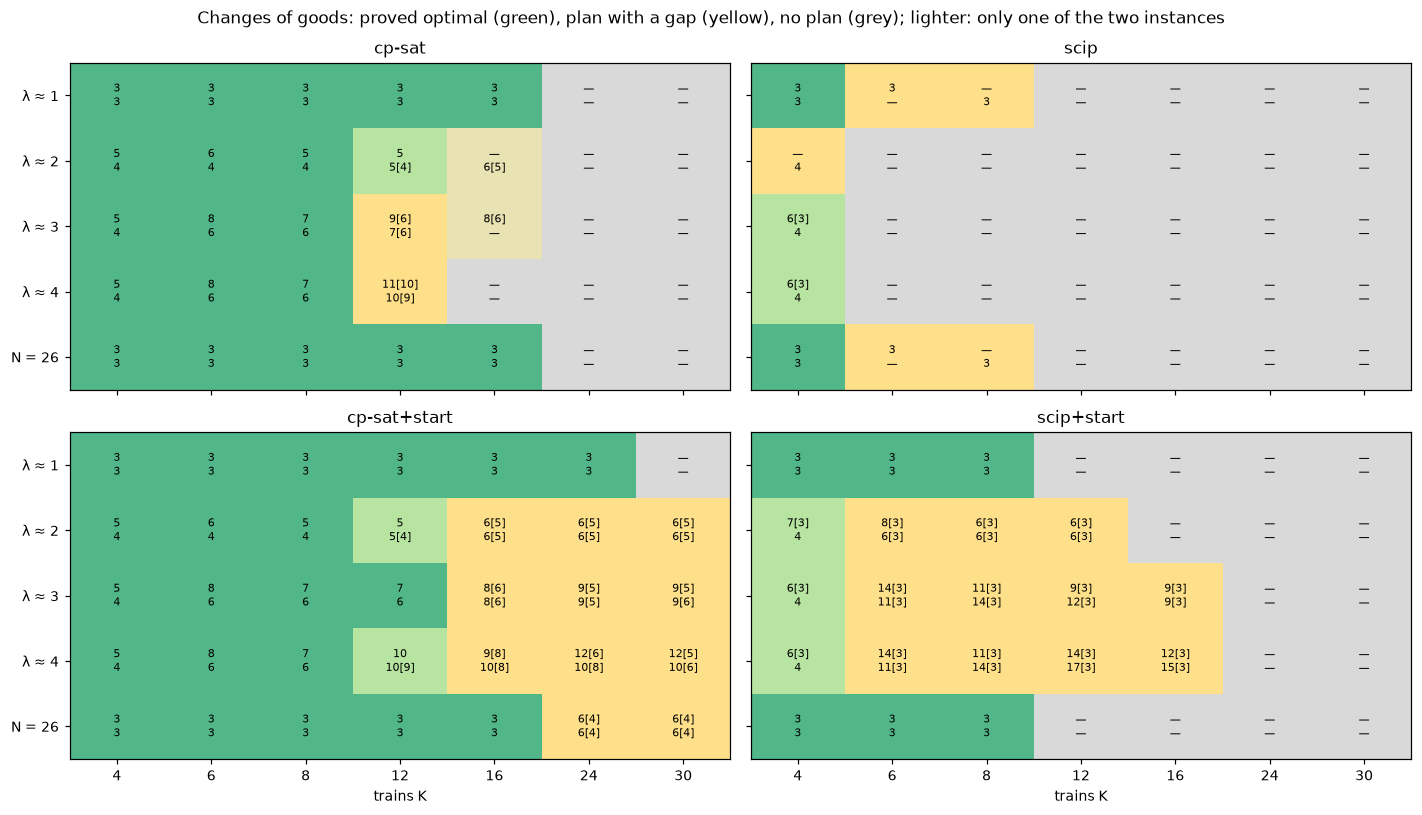

In [5]:
def score(row):
    return 2 if row.proved else 1 if row.found else 0

def cell_text(group):
    parts = []
    for _, r in group.sort_values("seed").iterrows():
        if r.proved:
            parts.append(f"{r.value:.0f}")
        elif r.found:
            parts.append(f"{r.value:.0f}[{r.bound:.0f}]")
        else:
            parts.append("—")
    return "\n".join(parts)

rows = ["λ ≈ 1", "λ ≈ 2", "λ ≈ 3", "λ ≈ 4", "N = 26"]
Ks = sorted(df.K.unique())
# mean score of the two instances: 0 no plan, 1 plan with a gap, 2 proved optimal
colors = ListedColormap(["#d9d9d9", "#e9e3b4", "#ffe08a", "#b7e4a1", "#52b788"])
levels = BoundaryNorm([-0.25, 0.25, 0.75, 1.25, 1.75, 2.25], colors.N)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, config in zip(axes.flat, CONFIGS):
    part = df[df.solver == config].copy()
    part["score"] = part.apply(score, axis=1)
    grid = part.pivot_table(index="label", columns="K", values="score", aggfunc="mean").reindex(index=rows, columns=Ks)
    ax.imshow(grid.values, cmap=colors, norm=levels, aspect="auto")
    for i, label in enumerate(rows):
        for j, k in enumerate(Ks):
            group = part[(part.label == label) & (part.K == k)]
            if len(group):
                ax.text(j, i, cell_text(group), ha="center", va="center", fontsize=7.5)
    ax.set_title(config)
    ax.set_xticks(range(len(Ks)), Ks)
    ax.set_yticks(range(len(rows)), rows)
for ax in axes[1]:
    ax.set_xlabel("trains K")
fig.suptitle("Changes of goods: proved optimal (green), plan with a gap (yellow), no plan (grey); lighter: only one of the two instances")
fig.tight_layout()

**Reading.**

- With a **tight buffer** (λ = 2–4) CP-SAT proves the optimum up to about
  **8 trains (70–80 wagons)**, sometimes 12. Beyond that the plans stay at a gap
  of one to a few changes.
- When **all wagons fit** (λ ≈ 1, and the reference buffer up to 16 trains)
  the optimum is the trivial |G| − 1 = 3 changes, and CP-SAT proves it up to
  16 trains — with a start up to 24. For more trains the model with 36–44 lanes
  becomes too large to finish within the minute, although the heuristic plan
  already reaches the bound.
- SCIP proves only the cases where the trivial bound is tight, and small
  instances.

### Why SCIP stalls: the lower bound

Each vertical bar is one instance, from the best lower bound up to the best
plan; a dot alone means the two meet (optimal). The dashed line is the trivial
bound |G| − 1 = 3, which is all the LP relaxation of the model gives.

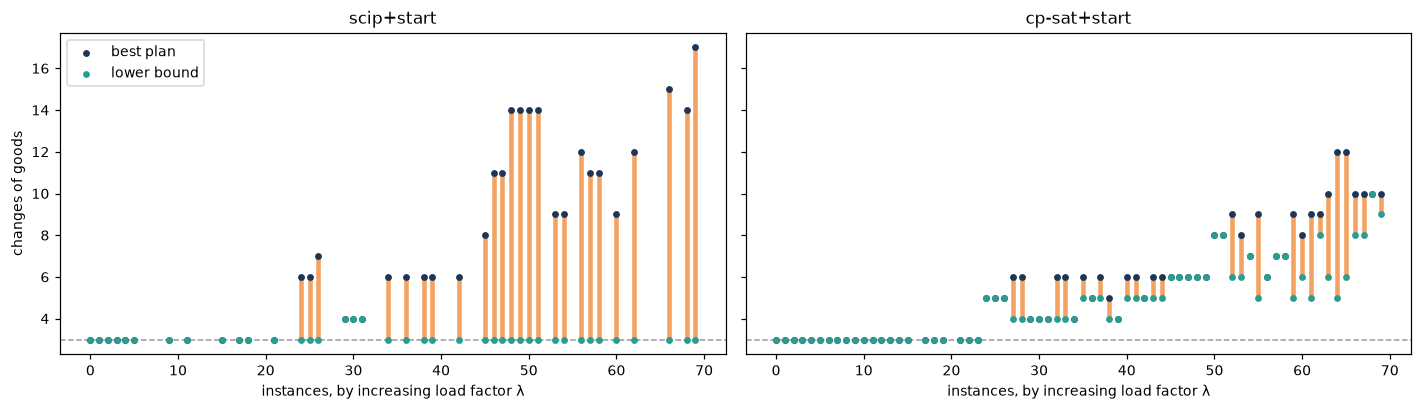

In [6]:
order = df[df.solver == "cp-sat+start"].sort_values(["load_factor"]).set_index(["series", "K", "target", "seed"]).index
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, config in zip(axes, ["scip+start", "cp-sat+start"]):
    part = df[df.solver == config].set_index(["series", "K", "target", "seed"]).reindex(order)
    x = np.arange(len(part))
    ok = part.found
    ax.vlines(x[ok], part.bound[ok], part.value[ok], color="#f4a261", lw=3)
    ax.scatter(x[ok], part.value[ok], s=12, color="#1d3557", zorder=3, label="best plan")
    ax.scatter(x[ok], part.bound[ok], s=12, color="#2a9d8f", zorder=3, label="lower bound")
    ax.axhline(3, ls="--", color="#999999", lw=1)
    ax.set_title(config)
    ax.set_xlabel("instances, by increasing load factor λ")
axes[0].set_ylabel("changes of goods")
axes[0].legend(loc="upper left")
fig.tight_layout()

**Reading.** The bounds of SCIP lie on the dashed line: the LP relaxation of
the model proves nothing beyond |G| − 1, because with fractional variables the
FIFO and departure constraints (big-M) hardly bind. CP-SAT raises the bound to
5–10 with its own reasoning on the binaries (propagation, conflict learning).
This is where a stronger formulation — valid inequalities for the changes —
would help most.

### Time and model size

Seconds to a proved optimum against the number of variables of the model, for
all runs that were proved optimal.

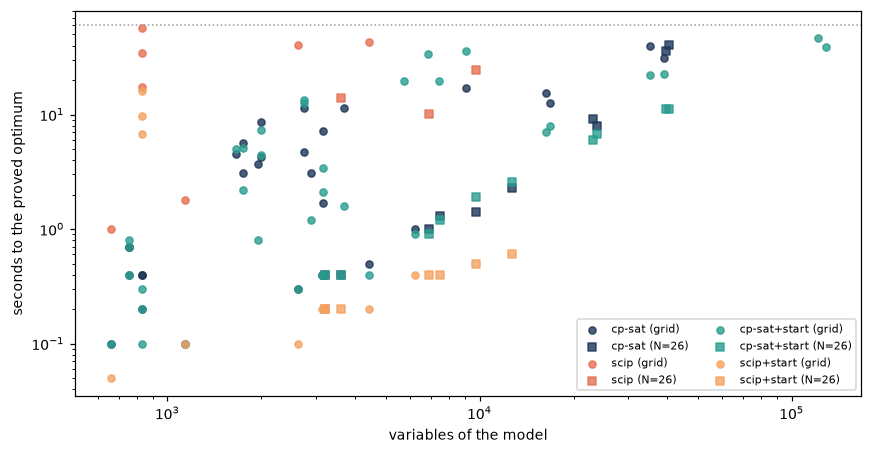

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
markers = {"grid": "o", "N=26": "s"}
for config, color in zip(CONFIGS, ["#1d3557", "#e76f51", "#2a9d8f", "#f4a261"]):
    part = df[(df.solver == config) & df.proved]
    for series, marker in markers.items():
        sub = part[part.series == series]
        ax.scatter(sub.variables, sub.seconds.clip(lower=0.05), s=22, color=color, marker=marker,
                   label=f"{config} ({series})" if len(sub) else None, alpha=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("variables of the model"); ax.set_ylabel("seconds to the proved optimum")
ax.axhline(60, color="#999999", ls=":", lw=1)
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()

**Reading.** CP-SAT solves models of up to about 40 000 variables to
optimality, often in seconds; the largest proved model has about 130 000. The
time limit (dotted) is reached long before memory or model building become an
issue — the hard part is the proof, not the size.

### What the MILP adds to the heuristic

The heuristic plan in waves (consecutive trains loaded together, one run per
goods type) is the start of the `+start` runs. Below the diagonal, the MILP
found fewer changes.

mean improvement over the heuristic: 1.51 changes, largest 8


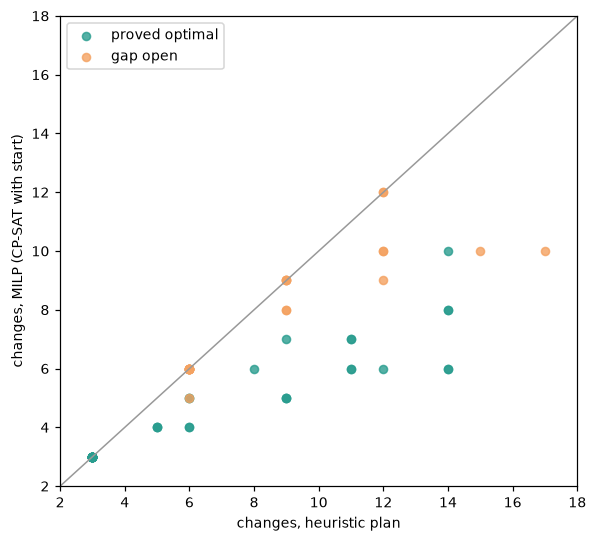

In [8]:
part = df[(df.solver == "cp-sat+start") & df.found]
fig, ax = plt.subplots(figsize=(5.5, 5))
for proved, color, label in [(True, "#2a9d8f", "proved optimal"), (False, "#f4a261", "gap open")]:
    sub = part[part.proved == proved]
    ax.scatter(sub.heuristic, sub.value, s=28, color=color, label=label, alpha=0.8)
top = max(part.heuristic.max(), part.value.max()) + 1
ax.plot([0, top], [0, top], color="#999999", lw=1)
ax.set_xlim(2, top); ax.set_ylim(2, top)
ax.set_xlabel("changes, heuristic plan"); ax.set_ylabel("changes, MILP (CP-SAT with start)")
ax.legend()
fig.tight_layout()
print("mean improvement over the heuristic:", f"{(part.heuristic - part.value).mean():.2f} changes,",
      f"largest {int((part.heuristic - part.value).max())}")

**Reading.** On medium instances the MILP saves many changes (e.g. 8 instead
of 14). On the largest ones the points sit on the diagonal: within the minute
the solver neither improves the heuristic plan nor proves it optimal.

### Running the benchmark again

The CSV files are written by `scripts/benchmark.py`. Rows that are already in
a results file are skipped, so a run can be interrupted and resumed.

```bash
make benchmark                        # the full grid, all four configurations (hours)
make report                           # regenerate docs/benchmark.md from the CSV files
scripts/watch_benchmark.sh            # follow the progress (Git Bash or Linux)
```

A small grid into a separate folder, without touching the published results:

```bash
.venv/Scripts/python scripts/benchmark.py run --configs cp-sat --trains 4,6,8 --load 2 --seeds 1,2 --csv out/check/cp-sat.csv
.venv/Scripts/python scripts/benchmark.py report --results "out/check/*.csv" --output out/check.md
```

## 2 · Are the plans right?

Three independent layers check every result:

1. **`simulate`** carries a plan out step by step without any knowledge of the
   model: it loads the wagons in order, lets every train leave as soon as it is
   complete, and reports a blocked lane, a lane over capacity, a missing wagon or
   a deadlock. It also computes the true values of all criteria.
2. **The exhaustive search** (`tests/exhaustive.py`) tries every loading order
   and every lane on tiny instances — 4 to 6 wagons — and finds the true
   lexicographic optimum, again without the model or its three facts.
3. **The tests** compare the two: on about a hundred tiny instances the MILP,
   with both solvers, several objectives, every symmetry breaking, a start and
   the spread, finds the same optimum as the exhaustive search — and reports
   *infeasible* exactly when no plan exists.

The cell below repeats the core of layer 3 live on twelve tiny instances.

In [9]:
from exhaustive import exhaustive
from test_model import tiny_instance

OBJECTIVE = "changes,lanes,waiting"
rows = []
for seed in range(12):
    instance = tiny_instance(seed)
    try:
        best, _ = exhaustive(instance, OBJECTIVE)
    except ValueError:
        best = None
    row = {"seed": seed, "wagons": instance.wagon_count, "lanes": instance.lanes,
           "λ": round(instance.load_factor, 2), "exhaustive": best}
    for solver in ("cp-sat", "scip"):
        plan = solve(instance, OBJECTIVE, ModelOptions(solver=solver, runs=instance.wagon_count))
        sim = simulate(instance, plan) if plan.has_plan else None
        row[solver] = sim.metrics.objective(tuple(OBJECTIVE.split(","))) if sim and not sim.errors else None
    row["agree"] = row["exhaustive"] == row["cp-sat"] == row["scip"]
    rows.append(row)
checks = pd.DataFrame(rows)
assert checks.agree.all()
checks

,seed,wagons,lanes,λ,exhaustive,cp-sat,scip,agree
0,0,4,3,1.04,"(1, 2, 6)","(1, 2, 6)","(1, 2, 6)",True
1,1,5,2,1.27,None,None,None,True
2,2,4,3,0.83,"(1, 2, 7)","(1, 2, 7)","(1, 2, 7)",True
3,3,5,1,1.57,"(2, 1, 9)","(2, 1, 9)","(2, 1, 9)",True
4,4,4,1,1.50,"(3, 1, 5)","(3, 1, 5)","(3, 1, 5)",True
5,5,6,1,1.00,"(1, 1, 9)","(1, 1, 9)","(1, 1, 9)",True
6,6,5,3,0.97,"(1, 3, 8)","(1, 3, 8)","(1, 3, 8)",True
7,7,5,2,1.03,"(2, 2, 11)","(2, 2, 11)","(2, 2, 11)",True
8,8,5,2,1.25,None,None,None,True
9,9,5,3,0.83,"(2, 2, 8)","(2, 2, 8)","(2, 2, 8)",True


**Reading.** Each tuple is (changes, lanes, waiting) of the lexicographic
optimum; `None` means that no valid plan exists, which both solvers then report
as infeasible. The full test suite (`make test`, 280 tests) runs the same
comparison on many more instances and objectives.

## 3 · Watching a plan

The three trains of [`docs/mip-model.md`](../docs/mip-model.md#example-three-trains):
T_1 = A, B; T_2 = B, A; T_3 = A, five wagons of 10 t and two lanes of 30 t. The
snapshots show the yard after selected events of the optimal plan — run 1
loads goods B, run 2 goods A, and wagon 1.1 needs a lane of its own.

optimal [((1, 2), 1), ((2, 1), 1), ((1, 1), 2), ((2, 2), 1), ((3, 1), 1)]


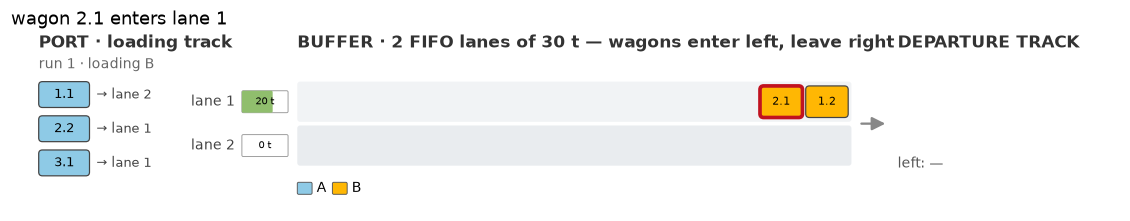

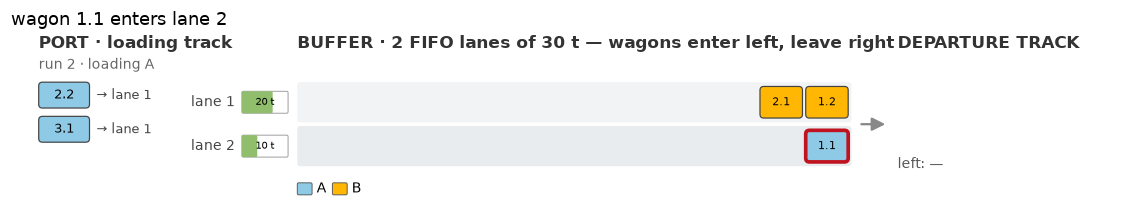

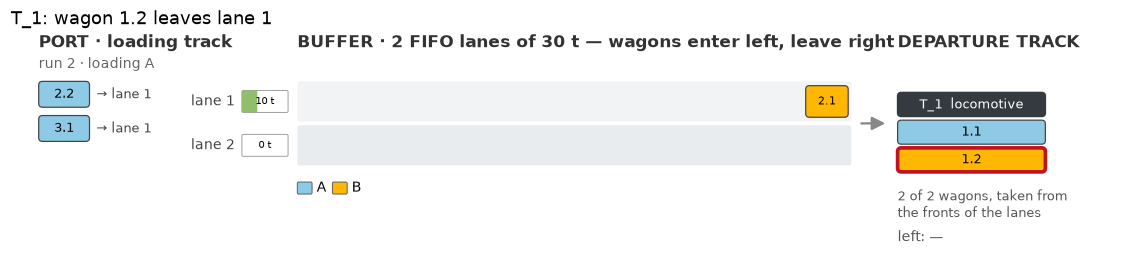

In [10]:
example = YardInstance(((("A", 10.0), ("B", 10.0)), (("B", 10.0), ("A", 10.0)), (("A", 10.0),)), lanes=2, capacity=30.0)
plan = solve(example, "changes,lanes,waiting,priority", ModelOptions(runs=5, threads=1))
print(plan.status.value, plan.loads)
states = yard_states(example, plan)
picks = [s for s in states if s.event == "load"][1:3] + [s for s in states if s.event == "pull"][1:2]
for state in picks:
    fig, ax = plt.subplots(figsize=(13, 3.6))
    draw_yard(ax, example, plan, state)
    what = {"load": f"wagon {state.wagon[0]}.{state.wagon[1]} enters lane {state.lane}",
            "pull": f"T_{state.train}: wagon {state.wagon[0]}.{state.wagon[1]} leaves lane {state.lane}"}[state.event]
    ax.set_title(what, fontsize=12, loc="left")
    plt.show()

### Interactive replay

A larger plan — 6 trains, 54 wagons, 4 lanes — replayed by the same viewer as
`make view`: play, pause, step, or drag the slider. (The viewer runs in the
browser; on GitHub the notebook is shown without it.)

In [11]:
instance = random_instance(trains=6, lanes=4, seed=3)
plan = solve(instance, "changes,lanes", ModelOptions(start=True, time_limit=30, threads=1))
print(plan.status.value, [f"{s.criterion} {s.value:g}" for s in plan.stages])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # IPython suggests IFrame, which needs a file; srcdoc keeps the notebook self-contained
    display(HTML(f'<iframe srcdoc="{escape(viewer_html(instance, plan))}" style="width:100%;height:900px;border:0"></iframe>'))

feasible ['changes 6', 'lanes 4']


## Next steps

- Stronger lower bounds on the changes (valid inequalities), so that the proof
  keeps up with the plans.
- A smaller model for many lanes: fewer h = a · z variables, the lookahead H.
- Time: loading times per wagon, setup times for a change of goods, and a
  timetable with departure times — and the question whether a MILP or a CP
  model with interval variables fits that better.